In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

In [3]:

mouse='cm126'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

figure_config_root = str(PREPARES / "config") + "/"
fetch_path_CLS = str(PREPARES / "CLS") + "/"
full_data_root = str(FIGURES / "movie8") + "/"

In [4]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
# palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

palatte_dict['RALM'] = palatte_dict['ALM']
palatte_dict['LALM'] = 'bisque'
palatte_dict['RRSP'] = palatte_dict['RSP']
palatte_dict['LRSP'] = 'sandybrown'
palatte_dict['RFP_M1_extra'] = 'tab:olive'
palatte_dict['LFP_M1_extra'] = 'tab:cyan'

palatte_dict['LholeMOp'] = '#ff964f' #pastel orange
palatte_dict['RholeMOp'] = '#ff964f' #pastel orange

palatte_dict['LT'] = '#b1d27b' # pale olive
palatte_dict['RT'] = '#b1d27b' # pale olive

palatte_dict['Lposterior'] = 'greenyellow'
palatte_dict['Rposterior'] = palatte_dict['Lposterior'] #'palegreen'

import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]

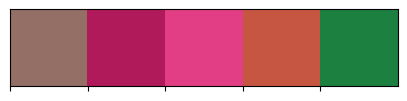

In [5]:
def hex_to_rgb(hex_value):
  h = hex_value.lstrip('#')
  return tuple(int(h[i:i + 2], 16) / 255.0 for i in (0, 2, 4))
# new_palette = ['#FFAE4E','#2A7377','#7B4EA1','#BAB2AC','#2C5B78']
new_palette = [palatte_dict['ALM'],palatte_dict['RV'],palatte_dict['LV'],
               palatte_dict['RSP'],palatte_dict['nose']]
rgb_colors = list(map(hex_to_rgb, new_palette))

sns.palplot(rgb_colors)

In [6]:
extra_bdp_color_dict = {
    'ALM-M2':palatte_dict['ALM'], 'RV-S1M1':palatte_dict['RV'],
                        'LV-S1M1':palatte_dict['RV'],'RSP-S1M1':palatte_dict['RSP'],
                        
                        'RALM':palatte_dict['ALM'],'LALM':palatte_dict['ALM'],
                        'RRSP':palatte_dict['RSP'],'LRSP':palatte_dict['RSP'],
                        
                  'RFP_M1_extra':palatte_dict['LFP'],
                        'LFP_M1_extra':palatte_dict['LFP'],
                       'median':palatte_dict['LV']}
palatte_dict['LV']=palatte_dict['RV']
palatte_dict['median_allM2'] = 'gray'
palatte_dict['globalM2_extra'] = palatte_dict['median_allM2']





In [7]:
palatte_dict = {**palatte_dict, **extra_bdp_color_dict}

In [8]:
all_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT','LFP', 'LHP',  'LW', 'LM', 'LN','LT']
all_bdps_list_M2 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RV','LFP', 'LHP',  'LW', 'LM', 'LN','LV']
all_bdps_list_M1 = [ 'RFP', 'RHP', 'LFP', 'LHP']
all_bdps_extra = ['RALM','LALM', 'RV', 'LV','RRSP','LRSP','RFP_M1_extra','LFP_M1_extra', 
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior'
                 ]
all_bdps_S1 = [bdp+'_S1' for bdp in all_bdps_list_S1]
all_bdps_M2 = [bdp+'_M2' for bdp in all_bdps_list_M2]
all_bdps_M1 = [bdp+'_M1' for bdp in all_bdps_list_M1]

all_bdps = all_bdps_extra + all_bdps_M2 + all_bdps_S1 + all_bdps_M1

In [9]:
full_data_root

'/Volumes/WX/scratch/figures_data/movie8/'

In [11]:
dict_W_masked = {}
for i_ax,mouse in enumerate(['cm229','cm128','cm126']):
    save_dict = load_pickle(fetch_path_CLS+'M2S1M1_NNLS_spatial_'+mouse)
    all_bdps_w_order = save_dict['all_bdps_w_order']
    full_M = save_dict['full_M']

    with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
            mask_midline = np.array(f_midline['mask_midline']).T
    
    if mouse == 'cm128':
        dict_st_movie_save = load_pickle(full_data_root+'integrated-single-trial-'+mouse)
    else:
        dict_st_movie_save = load_pickle(full_data_root+'run-single-trial-'+mouse)

    full_jrgeco = dict_st_movie_save['full_jrgeco']
    mask = np.mean(np.mean(full_jrgeco,-1),-1)>-1
    mask = mask.astype(float)
    mask[mask==0]=np.nan
    mask_reshape = mask.reshape((256*256))

    W_S1M2M1 = full_M[mask_reshape==1,:]

    # add M2-ones
    W_S1M2M1_M2 = []
    for i_key,key in enumerate(all_bdps_M2):
        ind_in_list = all_bdps.index(key)
        W_S1M2M1_M2.append(W_S1M2M1[:,ind_in_list])
    W_S1M2M1_M2_sum = np.clip(np.sum(np.stack(W_S1M2M1_M2,0),0), 0, 1)
    W_S1M2M1 = np.append(W_S1M2M1,W_S1M2M1_M2_sum[:,np.newaxis],axis=1)
    # add pan-cortical-ones
    W_S1M2M1 = np.append(W_S1M2M1,np.ones((len(W_S1M2M1_M2_sum),1)),axis=1)

    W_masked = np.zeros((256*256,W_S1M2M1.shape[-1]));W_masked[:]=np.nan
    W_masked[mask_reshape==1,:] = W_S1M2M1
    W_masked = W_masked.reshape((256,256,-1))
    
    dict_W_masked[mouse] = W_masked

In [13]:
body_part_short_dict = {'RFP_':'FP(R,','LFP_':'FP(L,',
                        'RHP_':'HP(R,','LHP_':'HP(L,',
                        'RW_':'whisker(R,','LW_':'whisker(L,',
                        'RM_':'mouth(R,','LM_':'mouth(L,',
                       'RV':'visual(R)','LV':'visual(L)',
                        
                        'RALM':'LAM(R)','LALM':'LAM(L)',
                        'RRSP':'RSP(R)','LRSP':'RSP(L)',
                        'RFP_M1_extra':'HL(R,S1)','LFP_M1_extra':'HL(L,S1)',
                       }

### piece together

In [14]:
import matplotlib.colors as mcolors
# palatte_dict.pop('tail')
# Convert hex colors to RGB
dict_rgb_colors = {}
for bdp in palatte_dict:
    dict_rgb_colors[bdp] = [mcolors.hex2color(palatte_dict[bdp])]
for bdp_w_label in extra_bdp_color_dict:
    dict_rgb_colors[bdp_w_label] = [mcolors.hex2color(extra_bdp_color_dict[bdp_w_label])]

dict_rgb_colors['LV']=dict_rgb_colors['RV-S1M1']
dict_rgb_colors['RV']=dict_rgb_colors['RV-S1M1']

dict_blended_brain_maps = {}
for i_ax,mouse in enumerate(['cm229','cm126','cm128']):
# for i_ax,mouse in enumerate(['cm229']):
    scaling = 1.3
    mask_3 = np.repeat(dict_W_masked[mouse][:,:,-1:],repeats=3,axis=-1)
    mask_3[mask_3==1]=0
    mask_3 = np.nan_to_num(mask_3.copy(),nan=scaling)

    dict_blended_brain_maps[mouse] =  {}

    for area in ['M2']:
        blended_image = np.zeros((256, 256, 3),dtype=np.float32)
        for i_M2, bdp in enumerate(all_bdps_list_M2):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_'+area)
            image = dict_W_masked[mouse][:,:,ind_in_list]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color
        dict_blended_brain_maps[mouse][area] = mask_3+blended_image
    for area in ['S1']:
        blended_image = np.zeros((256, 256, 3),dtype=np.float32)
        for i_M2, bdp in enumerate(all_bdps_list_S1):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_'+area)
            image = dict_W_masked[mouse][:,:,ind_in_list]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color
        dict_blended_brain_maps[mouse][area] = mask_3+blended_image
    for area in ['M1']:
        blended_image = np.zeros((256, 256, 3),dtype=np.float32)
        for i_M2, bdp in enumerate(all_bdps_list_M1):
            color = dict_rgb_colors[bdp.replace('L','R')]
            ind_in_list = all_bdps.index(bdp+'_'+area)
            image = dict_W_masked[mouse][:,:,ind_in_list]
            image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
            blended_image += image_scaled[:, :, np.newaxis] * color
        dict_blended_brain_maps[mouse][area] = mask_3+blended_image
    for bdp_extra in ['RFP_M1_extra', 'LFP_M1_extra']:
        color = dict_rgb_colors[bdp_extra.replace('L','R')]
        ind_in_list = all_bdps.index(bdp_extra)
        image = dict_W_masked[mouse][:,:,ind_in_list]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        dict_blended_brain_maps[mouse]['S1'] += mask_3+image_scaled[:, :, np.newaxis] * color

    blended_image = np.zeros((256, 256, 3),dtype=np.float32)
    for i_key,key in enumerate(['RALM','LALM', 'RV', 'LV','RRSP','LRSP',
                 'RholeMOp','LholeMOp',
                 'Rposterior','Lposterior']):
        ind_in_list = all_bdps.index(key)
        color = dict_rgb_colors[key]
        image = dict_W_masked[mouse][:,:,ind_in_list]
        image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
        blended_image += image_scaled[:, :, np.newaxis] * color


    ind_in_list = -2 # global M2
    color = dict_rgb_colors['globalM2_extra']
    image = dict_W_masked[mouse][:,:,ind_in_list]
    image_scaled = np.nan_to_num(np.array(image * scaling,dtype=np.float32),0)
    blended_image += image_scaled[:, :, np.newaxis] * color

    dict_blended_brain_maps[mouse]['extra'] = mask_3+blended_image


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [8.314681869359227e-20..3.9000000000000004].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [9.149465434964353e-18..1.38856041431427].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.3].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..3.9000000000000004

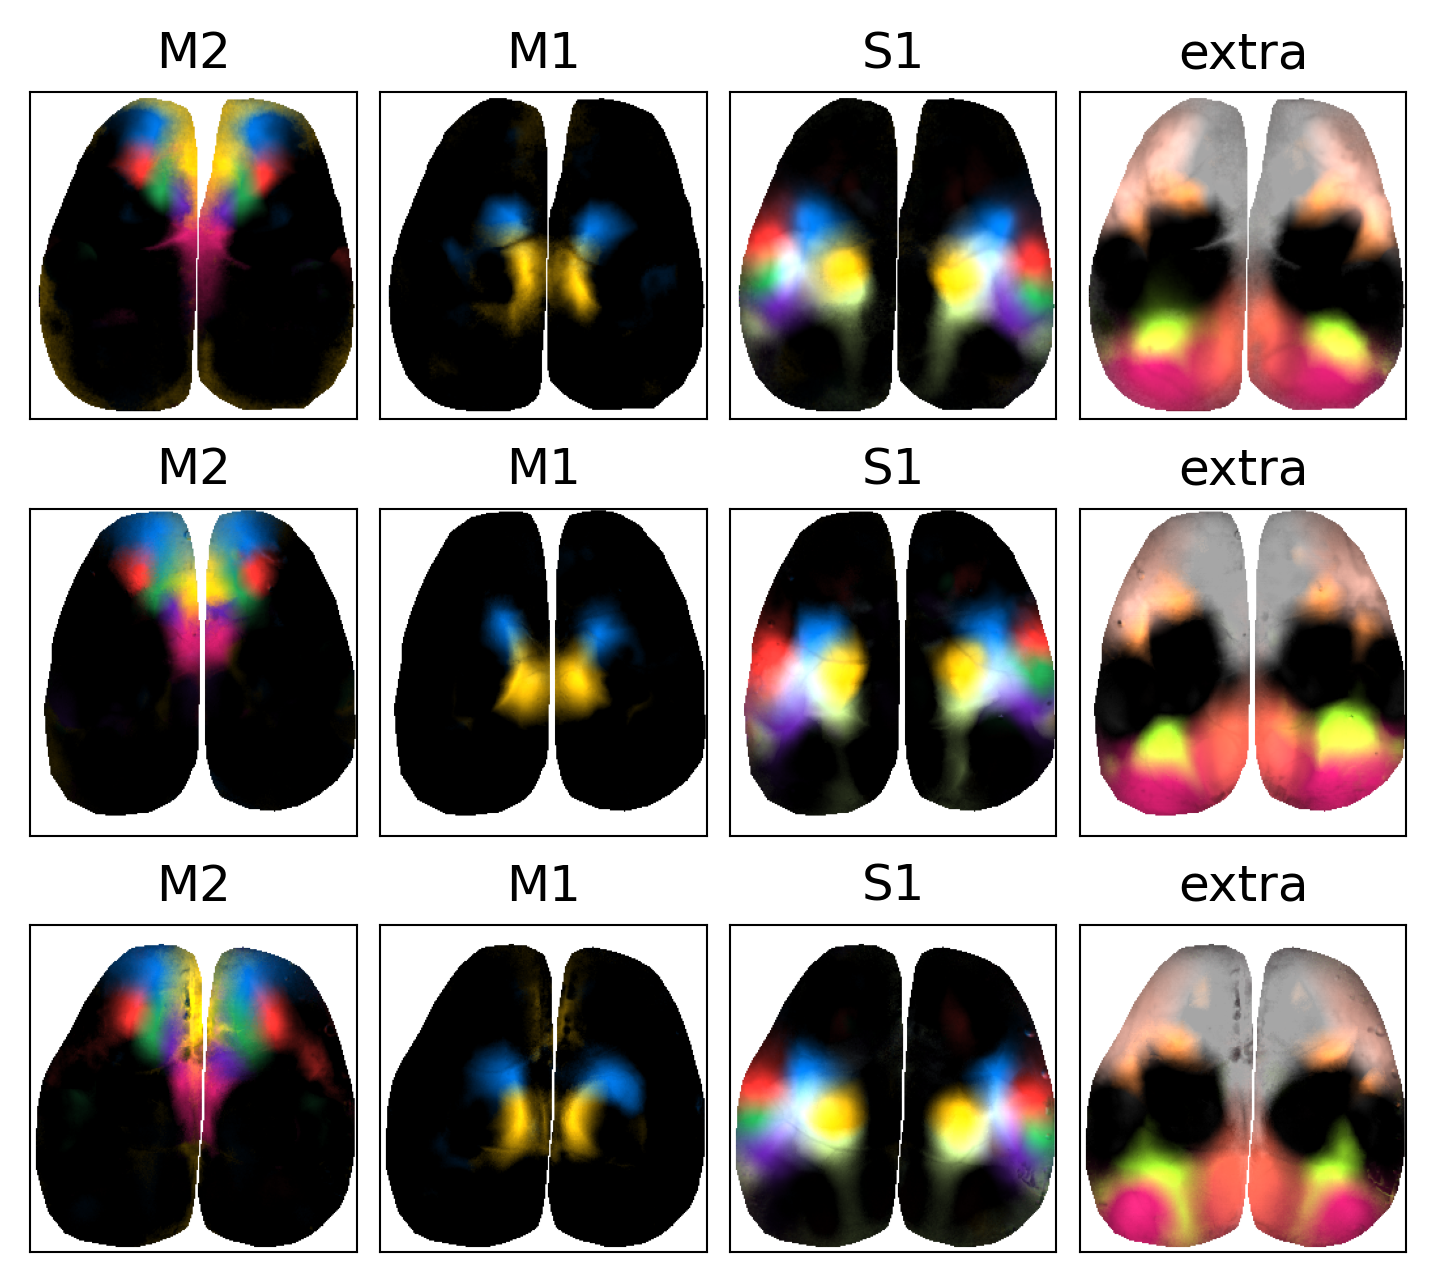

In [15]:
plt.style.use('default')
from matplotlib.gridspec import GridSpec
gs = GridSpec(100,100)
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

x_start = x_offset
x_stop = x_start+5
for i_ax in range(4):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
x_start = x_offset
x_stop = x_start+5
for i_ax in range(4,8):
    exec("ax{} = fig.add_subplot(gs[y_offset+6:y_offset+11,x_start:x_stop])".format(i_ax))
    # exec("ax{}.set_xlim([15,256]);ax{}.set_ylim([256,15])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
x_start = x_offset
x_stop = x_start+5
for i_ax in range(8,12):
    exec("ax{} = fig.add_subplot(gs[y_offset+12:y_offset+17,x_start:x_stop])".format(i_ax))
    exec("ax{}.set_xlim([6,256]);ax{}.set_ylim([256,6])".format(i_ax,i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
    x_start = x_stop
    x_stop = x_start+5
    
for i_ax_mouse,mouse_id in enumerate(['cm229','cm128','cm126']):
    for i_ax, area in enumerate(['M2','M1','S1','extra']):
        exec("ax{}.imshow(dict_blended_brain_maps[mouse_id][area])".format(i_ax+i_ax_mouse*4))
        exec("ax{}.set_title(area)".format(i_ax+i_ax_mouse*4))

for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(12):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue  
plt.subplots_adjust(wspace=0.5)

plt.savefig('fig7-P2-NNLS-pieced-together.svg',format='svg',dpi=300) 

# save legend

In [16]:
unique_bdps_list_S1 = [ 'RFP', 'RHP',  'RW', 'RM','RN','RT']
unique_bdps_list_M2 = [ 'RV',]
unique_bdps_extra = ['RALM', 'RRSP','RFP_M1_extra',
                 'RholeMOp',
                 'Rposterior',
                 ]

unique_bdps = unique_bdps_list_S1+unique_bdps_list_M2+unique_bdps_extra

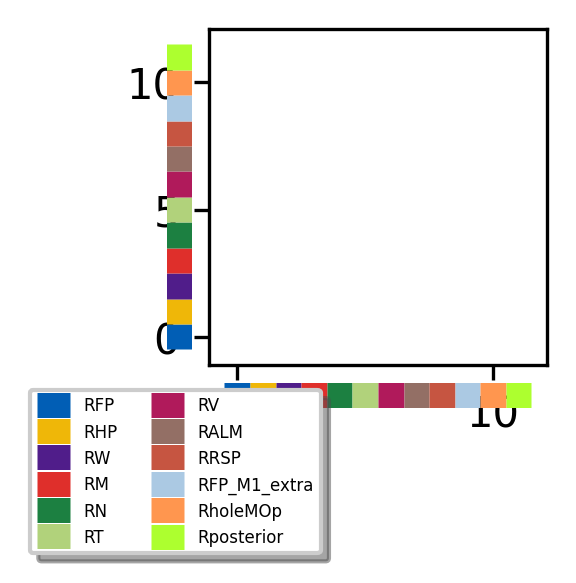

In [55]:
plt.style.use('default')

gs = GridSpec(100,100)

fmt = lambda x, pos: '{:.0%}'.format(x)

plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;

y_start = y_offset; y_stop = y_start+5
x_start = x_offset; x_stop = x_start+5

ax0 = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])
    
trans_x = ax0.get_xaxis_transform()
trans_y = ax0.get_yaxis_transform()
start=-0.5;
for bdp in unique_bdps:
    if 'ALM' in bdp:
        bdp_here='RALM'
    else:
        bdp_here = bdp.replace('L','R')
    stop = start + 1
    ax0.plot([start,stop],[-0.09,-0.09], color=palatte_dict[bdp_here],
            transform=trans_x,linewidth=6, clip_on=False,solid_capstyle='butt',label=bdp)
    ax0.plot([-.09,-.09],[start,stop], color=palatte_dict[bdp_here],
            transform=trans_y,linewidth=6, clip_on=False,solid_capstyle='butt')
    # ax2.annotate(bdp, xy=((stop+start)/2, -0.15), xycoords=trans_x, ha="center", va="top",fontsize=7,rotation=90)
    # if i_ax_temp == 0:
    #     ax2.annotate(bdp, xy=(-.25,(stop+start)/2-0.3), xycoords=trans_y, ha="center",fontsize=7, va="top")
    start = stop
ax0.legend(loc='upper center', bbox_to_anchor=(-0.1, -.05),
          ncol=2, fontsize=4,fancybox=True, shadow=True)
plt.savefig('fig7-P3-NNLS-pieced-together-legend.svg',format='svg',dpi=300) 

# DONE

# plot k selection curves for all mice

In [135]:
# mouse_id='cm229'

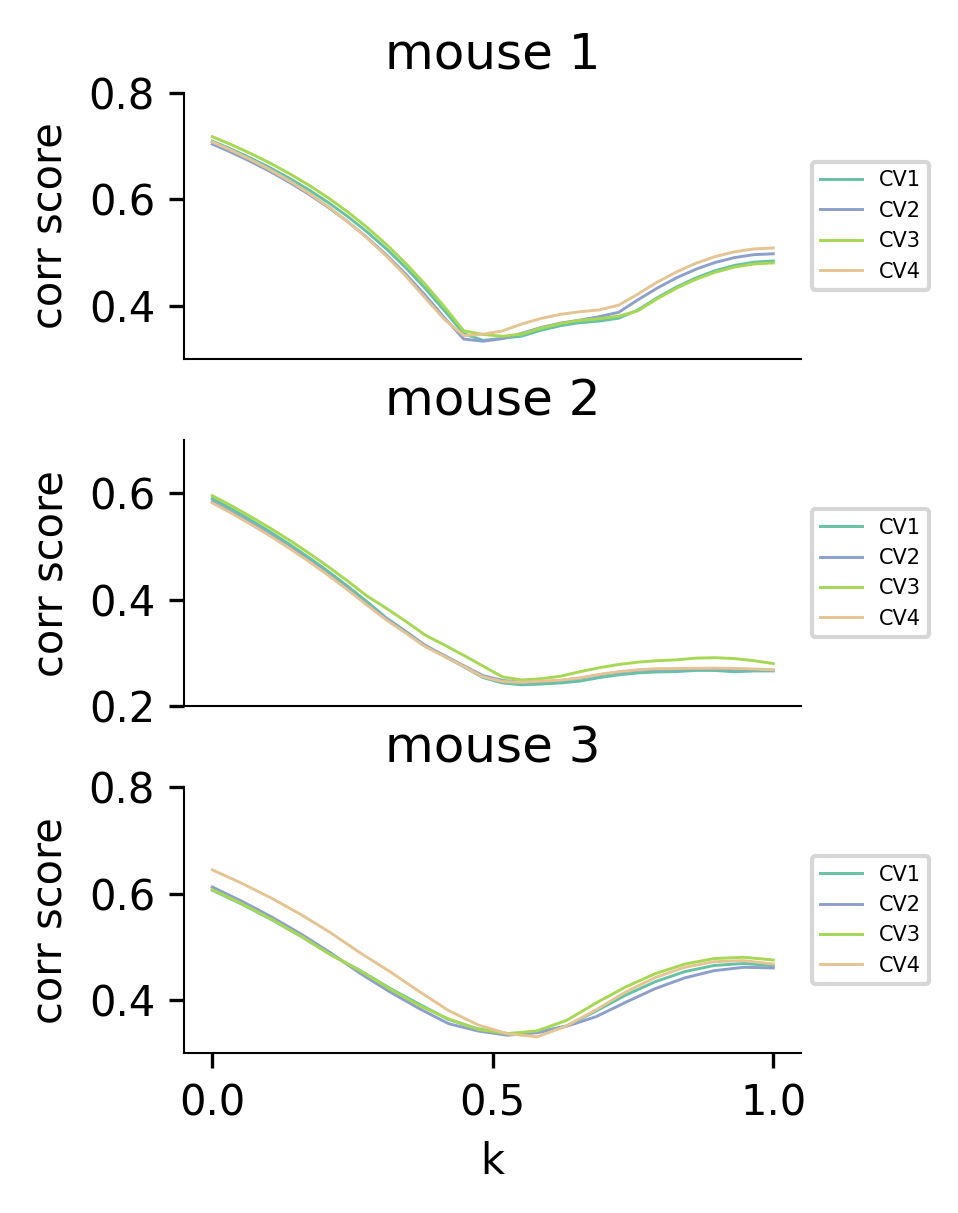

In [146]:
# plt.style.use('default')
# from matplotlib.gridspec import GridSpec
# gs = GridSpec(100,100)
# from matplotlib import ticker
# from matplotlib.ticker import FuncFormatter
# fmt = lambda x, pos: '{:.0%}'.format(x)
# temp_colors = sns.color_palette("Set2")

# plt.rcParams['svg.fonttype'] = 'none'
# fig = plt.figure(figsize=(30,30),dpi=300)

# y_offset = 20;x_offset=20;

# y_start = y_offset; y_stop = y_start+4
# x_start = x_offset; x_stop = x_start+9

# for i_ax in range(3):
#     exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
#     y_start = y_stop+1; y_stop = y_start+4
  
# for i_ax,mouse_id in enumerate(['cm229','cm125','cm126']):
    
#     load_path = prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-figures/special_edition_NNLS/'
#     dict_results_corr = load_pickle(load_path+'dict_results_corr_'+mouse_id)
#     ks = dict_results_corr['ks']
#     dict_score_corr = dict_results_corr['dict_score_corr']

#     for i_fold in range(4):
#         exec("ax{}.plot(ks,dict_score_corr[i_fold],color=temp_colors[i_fold*2],label='CV'+str(i_fold+1),linewidth=0.7)".format(i_ax))
#     exec("ax{}.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=5)".format(i_ax))
#     exec("ax{}.set_ylabel('corr score')".format(i_ax))
#     exec("ax{}.set_title('mouse '+str(i_ax+1))".format(i_ax))
#     if i_ax==1:
#         exec("ax{}.set_ylim([0.2,0.7])".format(i_ax))
#     else:
#         exec("ax{}.set_ylim([0.3,0.8])".format(i_ax))
    
# for axis in ['top','right','left','bottom']:
#     for i_ax in range(0,3):
#         try:
#             exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
#         except:
#             continue
# for axis in ['top','right']:
#     for i_ax in range(0,3):
#         exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        
# ax0.set_xticks([])
# ax1.set_xticks([])

# ax2.set_xlabel('k')
# plt.savefig('fig7-P3-corr-score-vs-k.svg',format='svg',dpi=300)